<a href="https://colab.research.google.com/github/kyalo-alfred/KnowledgeEngineering/blob/main/Autonomous_Trailer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Practical Exercise 4: Knowledge Engineering for the Autonomous Trailer

**Group members:** `ALFRED KYALO (190513)`, `IAN KABACHIA (171533)`, `<EHLERT KIYIEKA (170603)>`



## Step 1: Identify the Task

The trailer must travel between towns on Kenya's highway network and make safe driving decisions on the way.

**Goal:** reach the destination by the cheapest route in distance, and respond safely to traffic signals, obstacles, weather and road closures along the way.

The agent has to answer three kinds of question:
- Which route should I take from town A to town B, and how far is it?
- What should I do given the signal I can see, the weather and any obstacle ahead?
- What do I know about this town or road?

## Step 2: Assemble Relevant Knowledge

The agent needs to know:

- The towns, the region each one belongs to, and which towns are linked by a highway
- The driving distance of each link (km)
- The current condition of each road (open, roadworks or closed)
- The correct action for each traffic signal colour
- How weather changes the way the trailer should drive

**Sources.** The towns, links and distances come from our Practical Exercise 3 work (`design.md` and `UCS_Trailer.ipynb`), where distances were measured with Google Maps. The signal and weather rules were written by the group from the Kenyan Highway Code and general safe-driving practice. **No APIs or web scraping were used**, so there is no extra code to upload. A possible API-based improvement is discussed in Step 10.

## Step 3: Define the Vocabulary

**Predicates** (represented in Python as dictionaries and functions):

| Predicate | Meaning | Python representation |
|---|---|---|
| `Town(t)` | t is a town in the network | keys of `towns` |
| `Region(t, r)` | town t lies in region r | values of `towns` |
| `Road(a, b, km)` | a highway links a and b and is km long | `road_km[(a, b)]` |
| `Status(a, b, s)` | the road a-b has condition s | `road_status[(a, b)]` |
| `Signal(c)` | the trailer sees a signal of colour c | `signal_rules[c]` |
| `Weather(w)` | current weather is w | `weather_rules[w]` |

**Constants**

- Towns: Nairobi, Thika, Limuru, Murang'a, Nyeri, Nyahururu, Naivasha, Nakuru, Eldoret, Kericho, Kisumu, Kakamega
- Regions: Nairobi, Central Highlands, Rift Valley, Lake Victoria Basin
- Road statuses: open, roadworks, closed
- Signals: Red, Yellow, Green
- Weather: Clear, Light rain, Heavy rain

## Step 4: Encode General Knowledge about the Domain

Everything below is general knowledge about the domain. It does not describe one particular trip.

In [2]:
# Towns and the region each one belongs to
towns = {
    "Nairobi": "Nairobi",
    "Thika": "Nairobi",
    "Limuru": "Nairobi",
    "Murang'a": "Central Highlands",
    "Nyeri": "Central Highlands",
    "Nyahururu": "Central Highlands",
    "Naivasha": "Rift Valley",
    "Nakuru": "Rift Valley",
    "Eldoret": "Rift Valley",
    "Kericho": "Rift Valley",
    "Kisumu": "Lake Victoria Basin",
    "Kakamega": "Lake Victoria Basin",
}

# Highways: distance in km and condition. Every road works in both directions.
road_km = {}
road_status = {}

def add_road(a, b, km, status="open"):
    """Add a two-way road to the KB after checking both towns are known."""
    for t in (a, b):
        if t not in towns:
            print(f"Cannot add road: unknown town '{t}'. Use add_town() first.")
            return
    for x, y in ((a, b), (b, a)):
        road_km[(x, y)] = km
        road_status[(x, y)] = status

# Distances from Previous Exercises
for a, b, km in [
    ("Nairobi", "Thika", 42), ("Nairobi", "Limuru", 30), ("Nairobi", "Naivasha", 92),
    ("Limuru", "Naivasha", 65), ("Thika", "Murang'a", 40), ("Murang'a", "Nyeri", 60),
    ("Nyeri", "Nyahururu", 80), ("Nyahururu", "Nakuru", 90), ("Naivasha", "Nakuru", 62),
    ("Nakuru", "Kericho", 110), ("Kericho", "Kisumu", 100), ("Nakuru", "Eldoret", 150),
    ("Eldoret", "Kakamega", 110), ("Kakamega", "Kisumu", 52),
]:
    add_road(a, b, km)

# How much a road condition adds to the planning cost (1.0 = no change, None = unusable)
status_factor = {"open": 1.0, "roadworks": 1.2, "closed": None}

# Traffic signal rules
signal_rules = {
    "Red": "Stop. It is unsafe to move.",
    "Yellow": "Slow down and prepare to stop.",
    "Green": "Go. It is safe to proceed.",
}

# Weather rules
weather_rules = {
    "Clear": "Drive at the normal limit.",
    "Light rain": "Reduce speed and increase the following distance.",
    "Heavy rain": "Slow right down and stop at the next safe town if visibility drops.",
}

UNKNOWN_SIGNAL = "Unknown signal. Slow down and treat the junction as unsafe."

In [3]:
def show_kb():
    print("--- Towns ---")
    for t, r in towns.items():
        print(f"{t:10} : {r}")
    print("\n--- Roads (each listed once) ---")
    seen = set()
    for (a, b), km in road_km.items():
        if (b, a) in seen:
            continue
        seen.add((a, b))
        print(f"{a:10} <-> {b:10} {km:4} km  [{road_status[(a, b)]}]")
    print("\n--- Signal rules ---")
    for s, act in signal_rules.items():
        print(f"{s:10} -> {act}")
    print("\n--- Weather rules ---")
    for w, act in weather_rules.items():
        print(f"{w:10} -> {act}")

show_kb()

--- Towns ---
Nairobi    : Nairobi
Thika      : Nairobi
Limuru     : Nairobi
Murang'a   : Central Highlands
Nyeri      : Central Highlands
Nyahururu  : Central Highlands
Naivasha   : Rift Valley
Nakuru     : Rift Valley
Eldoret    : Rift Valley
Kericho    : Rift Valley
Kisumu     : Lake Victoria Basin
Kakamega   : Lake Victoria Basin

--- Roads (each listed once) ---
Nairobi    <-> Thika        42 km  [open]
Nairobi    <-> Limuru       30 km  [open]
Nairobi    <-> Naivasha     92 km  [open]
Limuru     <-> Naivasha     65 km  [open]
Thika      <-> Murang'a     40 km  [open]
Murang'a   <-> Nyeri        60 km  [open]
Nyeri      <-> Nyahururu    80 km  [open]
Nyahururu  <-> Nakuru       90 km  [open]
Naivasha   <-> Nakuru       62 km  [open]
Nakuru     <-> Kericho     110 km  [open]
Kericho    <-> Kisumu      100 km  [open]
Nakuru     <-> Eldoret     150 km  [open]
Eldoret    <-> Kakamega    110 km  [open]
Kakamega   <-> Kisumu       52 km  [open]

--- Signal rules ---
Red        -> Stop. 

## Step 5: Add New Facts to the Knowledge Base

Facts can be added directly in code, or through the interactive function at the end of this cell. The interactive call is commented out so the notebook runs from top to bottom without waiting for input. Remove the `#` to try it.

In [7]:
def add_town(name, region):
    towns[name.strip().title()] = region
    print(f"Added town: {name.strip().title()} ({region})")

def add_signal_rule(colour, action):
    signal_rules[colour.strip().capitalize()] = action
    print(f"Added signal rule: {colour.strip().capitalize()} -> {action}")

def set_road_status(a, b, status):
    """Change the condition of an existing road (open, roadworks or closed)."""
    if (a, b) not in road_km:
        print(f"No road between {a} and {b} in the KB.")
        return
    if status not in status_factor:
        print(f"Unknown status '{status}'. Use one of {list(status_factor)}.")
        return
    road_status[(a, b)] = status
    road_status[(b, a)] = status
    print(f"Road {a} <-> {b} is now {status}")

# Adding facts directly
add_signal_rule("Flashing", "Stop, check the intersection, then proceed when clear.")
add_town("Gilgil", "Rift Valley")
add_road("Naivasha", "Gilgil", 35)
add_road("Gilgil", "Nakuru", 27)

def add_fact_interactive():
    """Ask the user for a new road and add it to the KB."""
    a = input("From town: ").strip().title()
    b = input("To town: ").strip().title()
    km = float(input("Distance in km: "))
    add_road(a, b, km)

def add_fact_interactive():
    """Ask the user for a new road, add unknown towns first, and confirm."""
    a = input("From town: ").strip().title()
    b = input("To town: ").strip().title()
    for t in (a, b):
        if t not in towns:
            region = input(f"{t} is not in the KB. Which region is it in? ")
            add_town(t, region.strip().title())
    km = float(input("Distance in km: "))
    add_road(a, b, km)
    print(f"Added road: {a} <-> {b} ({km:g} km)")

add_fact_interactive()
show_kb()

Added signal rule: Flashing -> Stop, check the intersection, then proceed when clear.
Added town: Gilgil (Rift Valley)
From town: Thika
To town: Kisumu
Distance in km: 57
Added road: Thika <-> Kisumu (57 km)
--- Towns ---
Nairobi    : Nairobi
Thika      : Nairobi
Limuru     : Nairobi
Murang'a   : Central Highlands
Nyeri      : Central Highlands
Nyahururu  : Central Highlands
Naivasha   : Rift Valley
Nakuru     : Rift Valley
Eldoret    : Rift Valley
Kericho    : Rift Valley
Kisumu     : Lake Victoria Basin
Kakamega   : Lake Victoria Basin
Gilgil     : Rift Valley

--- Roads (each listed once) ---
Nairobi    <-> Thika        42 km  [open]
Nairobi    <-> Limuru       30 km  [open]
Nairobi    <-> Naivasha     92 km  [open]
Limuru     <-> Naivasha     65 km  [open]
Thika      <-> Murang'a     40 km  [open]
Murang'a   <-> Nyeri        60 km  [open]
Nyeri      <-> Nyahururu    80 km  [open]
Nyahururu  <-> Nakuru       90 km  [open]
Naivasha   <-> Nakuru       62 km  [open]
Nakuru     <-> Keri

Gilgil was added as a new town between Naivasha and Nakuru. Going through it costs 35 + 27 = 62 km, the same as the direct Naivasha to Nakuru road, so the planner now has two equally short options there and returns the direct one.

## Steps 6 and 7: Encode a Specific Problem Instance and Pose Queries

**Step 6** records what the trailer observes right now (the specific facts of this trip).

**Step 7** poses queries to the KB. Two functions do the reasoning:

- `plan_route` runs Uniform Cost Search over the roads that the KB says are usable, adding 20 percent to the cost of roads under roadworks.
- `decide_action` combines the signal, weather and obstacle facts. An obstacle overrides everything else, then the signal rule is applied, then the weather advice is added.

In [ ]:
import heapq

def usable_neighbours(town):
    """Return (neighbour, planning_cost, real_km) for roads that are not closed."""
    out = []
    for (a, b), km in road_km.items():
        if a != town:
            continue
        factor = status_factor[road_status[(a, b)]]
        if factor is None:
            continue
        out.append((b, km * factor, km))
    return out

def plan_route(start, goal):
    """Uniform Cost Search over the KB. Returns (path, planning_cost, real_km) or None."""
    if start not in towns or goal not in towns:
        return None
    counter = 0
    frontier = [(0, counter, start, [start], 0)]
    best = {start: 0}
    explored = set()
    while frontier:
        g, _, town, path, real = heapq.heappop(frontier)
        if town in explored:
            continue
        if town == goal:
            return path, g, real
        explored.add(town)
        for nxt, cost, km in usable_neighbours(town):
            new_g = g + cost
            if nxt not in explored and new_g < best.get(nxt, float("inf")):
                best[nxt] = new_g
                counter += 1
                heapq.heappush(frontier, (new_g, counter, nxt, path + [nxt], real + km))
    return None

def decide_action(signal, weather="Clear", obstacle=False):
    """Choose a driving action from the signal, weather and obstacle facts."""
    if obstacle:
        return "Brake and stop. Obstacle ahead."
    action = signal_rules.get(signal.strip().capitalize(), UNKNOWN_SIGNAL)
    if signal.strip().capitalize() == "Red":
        return action          # stopped, so weather advice adds nothing
    advice = weather_rules.get(weather, "Weather not recognised. Drive cautiously.")
    return f"{action} {advice}"

In [ ]:
# Step 6: the current observation from sensors and the trip request
observation = {
    "location": "Nairobi",
    "destination": "Kisumu",
    "signal": "Green",
    "weather": "Light rain",
    "obstacle": False,
}

# Step 7: query the KB
result = plan_route(observation["location"], observation["destination"])

print("=== Autonomous Trailer Decision System ===")
print(f"Location    : {observation['location']}")
print(f"Destination : {observation['destination']}")
if result:
    path, cost, km = result
    print("Route       :", " -> ".join(path))
    print(f"Distance    : {km:g} km")
else:
    print("Route       : none available")
print("Driving     :", decide_action(observation["signal"], observation["weather"], observation["obstacle"]))

=== Autonomous Trailer Decision System ===
Location    : Nairobi
Destination : Kisumu
Route       : Nairobi -> Naivasha -> Nakuru -> Kericho -> Kisumu
Distance    : 364 km
Driving     : Go. It is safe to proceed. Reduce speed and increase the following distance.


## Step 8: Querying the Knowledge Base

In [ ]:
def region_of(town):
    return towns.get(town, "Unknown town")

def towns_in(region):
    return [t for t, r in towns.items() if r == region]

def direct_distance(a, b):
    return road_km.get((a, b), "No direct road")

def neighbours_of(town):
    return sorted(b for (a, b) in road_km if a == town)

print("Region of Kericho        :", region_of("Kericho"))
print("Towns in Rift Valley     :", towns_in("Rift Valley"))
print("Neighbours of Nakuru     :", neighbours_of("Nakuru"))
print("Nairobi to Naivasha (km) :", direct_distance("Nairobi", "Naivasha"))
print("Nairobi to Kisumu (km)   :", direct_distance("Nairobi", "Kisumu"))

print()
for src, dst in [("Nairobi", "Nakuru"), ("Nairobi", "Eldoret"), ("Thika", "Kericho")]:
    path, cost, km = plan_route(src, dst)
    print(f"{src} to {dst}: {' -> '.join(path)} ({km:g} km)")

print()
print("Red light, clear          :", decide_action("Red", "Clear"))
print("Yellow, heavy rain        :", decide_action("Yellow", "Heavy rain"))
print("Green with obstacle       :", decide_action("Green", "Clear", obstacle=True))

Region of Kericho        : Rift Valley
Towns in Rift Valley     : ['Naivasha', 'Nakuru', 'Eldoret', 'Kericho', 'Gilgil']
Neighbours of Nakuru     : ['Eldoret', 'Gilgil', 'Kericho', 'Naivasha', 'Nyahururu']
Nairobi to Naivasha (km) : 92
Nairobi to Kisumu (km)   : No direct road

Nairobi to Nakuru: Nairobi -> Naivasha -> Nakuru (154 km)
Nairobi to Eldoret: Nairobi -> Naivasha -> Nakuru -> Eldoret (304 km)
Thika to Kericho: Thika -> Nairobi -> Naivasha -> Nakuru -> Kericho (306 km)

Red light, clear          : Stop. It is unsafe to move.
Yellow, heavy rain        : Slow down and prepare to stop. Slow right down and stop at the next safe town if visibility drops.
Green with obstacle       : Brake and stop. Obstacle ahead.


## Step 9: Debugging the Knowledge Base

These tests push the KB with bad or awkward input to see how the agent reacts. Road closures are undone after each test so later cells are not affected.

In [ ]:
print("--- Unknown or odd signals and weather ---")
for sig, wx in [("Red", "Clear"), ("Blue", "Clear"), ("Teal", "Heavy rain"),
                ("None", "Clear"), ("Green", "Snow")]:
    print(f"Signal {sig:6} Weather {wx:10} -> {decide_action(sig, wx)}")

print("\n--- Route planning edge cases ---")
print("Unknown town (Mombasa):", plan_route("Nairobi", "Mombasa"))
print("Start equals goal     :", plan_route("Nairobi", "Nairobi"))

print("\n--- Closure forces a reroute ---")
set_road_status("Nakuru", "Kericho", "closed")
path, cost, km = plan_route("Nairobi", "Kisumu")
print(f"With Nakuru-Kericho closed: {' -> '.join(path)} ({km:g} km)")
set_road_status("Nakuru", "Kericho", "open")

print("\n--- Roadworks adds cost but road stays usable ---")
set_road_status("Kericho", "Kisumu", "roadworks")
path, cost, km = plan_route("Nairobi", "Kisumu")
print(f"With Kericho-Kisumu under roadworks: {' -> '.join(path)} ({km:g} km, planning cost {cost:g})")
set_road_status("Kericho", "Kisumu", "open")

print("\n--- Kisumu cut off completely ---")
set_road_status("Kericho", "Kisumu", "closed")
set_road_status("Kakamega", "Kisumu", "closed")
print("Route to Kisumu:", plan_route("Nairobi", "Kisumu"))
set_road_status("Kericho", "Kisumu", "open")
set_road_status("Kakamega", "Kisumu", "open")

--- Unknown or odd signals and weather ---
Signal Red    Weather Clear      -> Stop. It is unsafe to move.
Signal Blue   Weather Clear      -> Unknown signal. Slow down and treat the junction as unsafe. Drive at the normal limit.
Signal Teal   Weather Heavy rain -> Unknown signal. Slow down and treat the junction as unsafe. Slow right down and stop at the next safe town if visibility drops.
Signal None   Weather Clear      -> Unknown signal. Slow down and treat the junction as unsafe. Drive at the normal limit.
Signal Green  Weather Snow       -> Go. It is safe to proceed. Weather not recognised. Drive cautiously.

--- Route planning edge cases ---
Unknown town (Mombasa): None
Start equals goal     : (['Nairobi'], 0, 0)

--- Closure forces a reroute ---
Road Nakuru <-> Kericho is now closed
With Nakuru-Kericho closed: Nairobi -> Naivasha -> Nakuru -> Eldoret -> Kakamega -> Kisumu (466 km)
Road Nakuru <-> Kericho is now open

--- Roadworks adds cost but road stays usable ---
Road Kerich

What the tests show:

- An unknown signal falls back to the safe default instead of crashing.
- An unknown weather value still returns the signal action with a caution note.
- A town that is not in the KB returns `None`, so the caller must check for that.
- A closed road changes the route, and a closed road that cuts off the destination gives no route at all.
- Roadworks raised the planning cost to 1.2 times the distance but the trailer still used the road, because the alternative via Eldoret and Kakamega was much longer.

## Step 10: Final Reflection

**Challenges**

- The distances are typed in by hand, so one wrong number changes the optimal route without any warning. Checking them against the Practical Exercise 3 results was the only safeguard.
- It was not always clear what belongs in the KB and what belongs in the reasoning code. Closures and roadworks are facts, but the 20 percent roadworks penalty is a rule, so it sits in `status_factor`.
- An obstacle has to outrank the signal. A green light does not make it safe to drive into a stalled vehicle, so `decide_action` checks obstacles first.
- The KB is static. It only knows what was typed in, so it cannot tell that a road became blocked an hour ago.

**Possible improvements**

- Pull distances and travel times from a routing API such as Google Directions or OpenStreetMap's OSRM instead of typing them.
- Feed live traffic and weather data into `road_status` and the weather facts.
- Switch from Uniform Cost Search to A* with straight-line distance as the heuristic, which would expand fewer towns.
- Save the KB to a JSON file so facts added at run time are kept between sessions.
- Add more of the Kenyan network, including Mombasa and the northern corridor, plus rules for night driving and axle load limits.



## Team Evidence

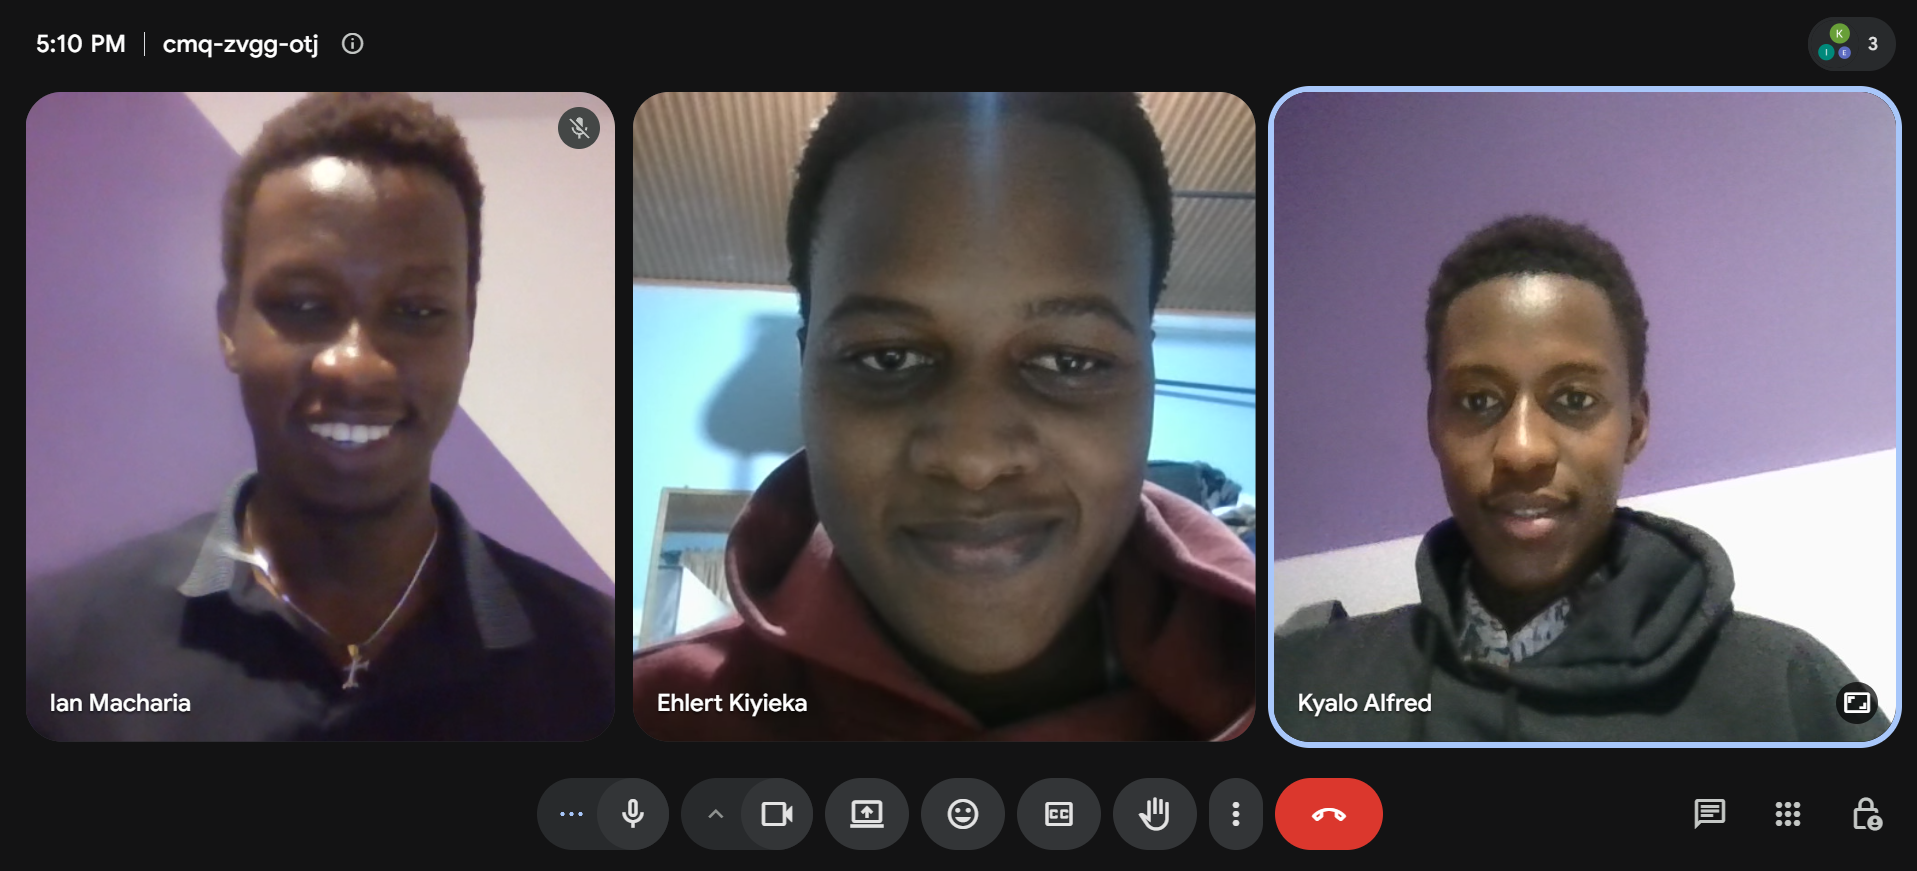